In [2]:
!pip install pymoo matplotlib numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 18.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 879.5/879.5 kB 18.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [pymoo]


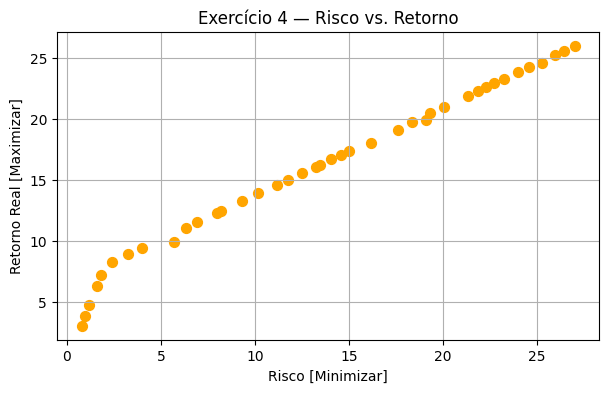

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize

class PortfolioProblem(ElementwiseProblem):
    def __init__(self):
        super().__init__(n_var=2, n_obj=2, xl=np.array([0.0, 0.0]), xu=np.array([100.0, 100.0]))

    def _evaluate(self, x, out, *args, **kwargs):
        rf, acoes = x[0], x[1]

        # TODO 1: Retorno esperado negativo para ser minimizado
        f1_retorno_negativo = -(rf * 0.08 + acoes * 0.18)

        # TODO 2: Risco (Minimizar)
        f2_risco = (rf * 0.02 + acoes * 0.25)

        out["F"] = [f1_retorno_negativo, f2_risco]

# TODO 3: Executar NSGA-II e plotar
res4 = minimize(PortfolioProblem(), NSGA2(pop_size=40), termination=('n_gen', 50), seed=4)

plt.figure(figsize=(7, 4))
# Revertendo o sinal do retorno para o gráfico ficar intuitivo (maior é melhor no eixo Y)
plt.scatter(res4.F[:, 1], -res4.F[:, 0], color='orange', s=50)
plt.title("Exercício 4 — Risco vs. Retorno")
plt.xlabel("Risco [Minimizar]")
plt.ylabel("Retorno Real [Maximizar]")
plt.grid(True)
plt.show()